
# Regression Methods: Side-by-Side Comparison




In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.datasets import load_diabetes

# Display options
np.set_printoptions(suppress=True, precision=4)
pd.set_option('display.precision', 4)



## 1. Simple & Polynomial Regression on 1D Synthetic Data

We'll generate a simple dataset with a known curved relationship and then:
- Fit **Simple Linear** (line)
- Fit **Polynomial (degree=2)** (curve)
- Visualize and compare metrics


In [2]:

# Generate 1D synthetic data
rng = np.random.default_rng(42)
X_1d = np.linspace(-3, 3, 160).reshape(-1, 1)
y_1d = (1.5*X_1d**2 - 2*X_1d + 5 + rng.normal(0, 0.8, size=X_1d.shape)).ravel()

X1_tr, X1_te, y1_tr, y1_te = train_test_split(X_1d, y_1d, test_size=0.2, random_state=42)

# Simple Linear
lin1 = LinearRegression().fit(X1_tr, y1_tr)
y1_pred_lin = lin1.predict(X1_te)
lin1_mae = mean_absolute_error(y1_te, y1_pred_lin)
lin1_rmse = np.sqrt(mean_squared_error(y1_te, y1_pred_lin))
lin1_r2 = r2_score(y1_te, y1_pred_lin)

print(f"Simple Linear (1D) -> MAE={lin1_mae:.3f}, RMSE={lin1_rmse:.3f}, R2={lin1_r2:.3f}")
print(f"Slope={lin1.coef_[0]:.3f}, Intercept={lin1.intercept_:.3f}")


Simple Linear (1D) -> MAE=3.374, RMSE=3.709, R2=0.552
Slope=-1.928, Intercept=9.555


In [3]:

# Polynomial (degree=2)
poly = PolynomialFeatures(degree=2, include_bias=False)
X1_tr_p = poly.fit_transform(X1_tr)
X1_te_p = poly.transform(X1_te)

lin2 = LinearRegression().fit(X1_tr_p, y1_tr)
y1_pred_poly = lin2.predict(X1_te_p)
poly_mae = mean_absolute_error(y1_te, y1_pred_poly)
poly_rmse = np.sqrt(mean_squared_error(y1_te, y1_pred_poly))
poly_r2 = r2_score(y1_te, y1_pred_poly)

print(f"Polynomial d=2 (1D) -> MAE={poly_mae:.3f}, RMSE={poly_rmse:.3f}, R2={poly_r2:.3f}")
print('Features:', poly.get_feature_names_out(['x']))


Polynomial d=2 (1D) -> MAE=0.604, RMSE=0.739, R2=0.982
Features: ['x' 'x^2']


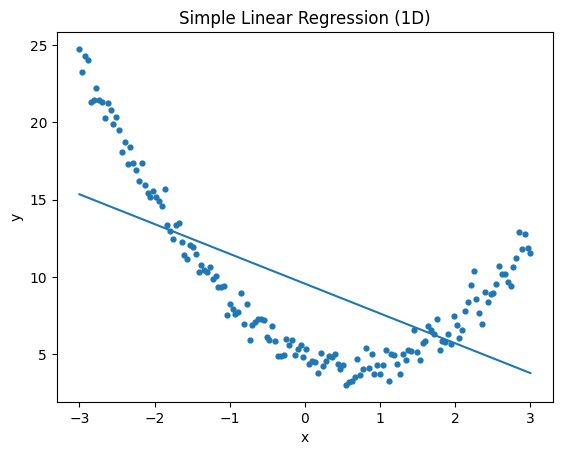

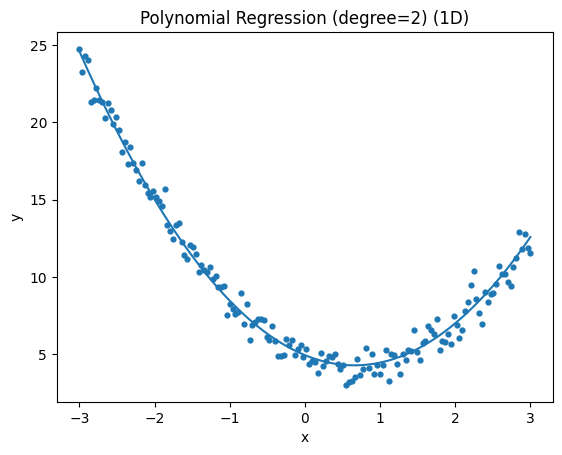

In [4]:

# Visualize fits on full X grid (1 plot per chart)
# Simple linear fit
plt.scatter(X_1d, y_1d, s=12)
plt.plot(X_1d, lin1.predict(X_1d))
plt.title("Simple Linear Regression (1D)")
plt.xlabel("x"); plt.ylabel("y"); plt.show()

# Polynomial fit
X1_full_p = poly.transform(X_1d)
plt.scatter(X_1d, y_1d, s=12)
plt.plot(X_1d, lin2.predict(X1_full_p))
plt.title("Polynomial Regression (degree=2) (1D)")
plt.xlabel("x"); plt.ylabel("y"); plt.show()



## 2. Multiple, Ridge, and Lasso on the Diabetes Dataset

We'll use scikit-learn's **Diabetes** dataset (10 features). We'll apply:
- **Multiple Linear Regression** (baseline)
- **Ridge** with cross-validated alpha
- **Lasso** with cross-validated alpha

Then we'll compare all three on the same train/test split.


In [5]:

# Load data
X, y = load_diabetes(return_X_y=True)
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42)

# Multiple Linear Regression (with scaling for fair comparison)
pipe_lin = Pipeline([
    ("scaler", StandardScaler()),
    ("lin", LinearRegression())
]).fit(X_tr, y_tr)
yp_lin = pipe_lin.predict(X_te)
mlr_mae = mean_absolute_error(y_te, yp_lin)
mlr_rmse = np.sqrt(mean_squared_error(y_te, yp_lin))
mlr_r2 = r2_score(y_te, yp_lin)
print(f"Multiple Linear -> MAE={mlr_mae:.3f}, RMSE={mlr_rmse:.3f}, R2={mlr_r2:.3f}")

# RidgeCV
pipe_ridge = Pipeline([
    ("scaler", StandardScaler()),
    ("ridge", RidgeCV(alphas=np.logspace(-3, 3, 25), cv=5))
]).fit(X_tr, y_tr)
yp_ridge = pipe_ridge.predict(X_te)
ridge_mae = mean_absolute_error(y_te, yp_ridge)
ridge_rmse = np.sqrt(mean_squared_error(y_te, yp_ridge))
ridge_r2 = r2_score(y_te, yp_ridge)
best_alpha_ridge = pipe_ridge.named_steps["ridge"].alpha_
print(f"Ridge -> alpha={best_alpha_ridge:.4f}, MAE={ridge_mae:.3f}, RMSE={ridge_rmse:.3f}, R2={ridge_r2:.3f}")

# LassoCV
pipe_lasso = Pipeline([
    ("scaler", StandardScaler()),
    ("lasso", LassoCV(alphas=np.logspace(-3, 1, 30), cv=5, max_iter=5000, random_state=42))
]).fit(X_tr, y_tr)
yp_lasso = pipe_lasso.predict(X_te)
lasso_mae = mean_absolute_error(y_te, yp_lasso)
lasso_rmse = np.sqrt(mean_squared_error(y_te, yp_lasso))
lasso_r2 = r2_score(y_te, yp_lasso)
best_alpha_lasso = pipe_lasso.named_steps["lasso"].alpha_
nonzero = (pipe_lasso.named_steps["lasso"].coef_ != 0).sum()
print(f"Lasso -> alpha={best_alpha_lasso:.4f}, nonzero={nonzero}/{X.shape[1]}, MAE={lasso_mae:.3f}, RMSE={lasso_rmse:.3f}, R2={lasso_r2:.3f}")


Multiple Linear -> MAE=42.794, RMSE=53.853, R2=0.453
Ridge -> alpha=31.6228, MAE=42.949, RMSE=53.493, R2=0.460
Lasso -> alpha=1.4874, nonzero=8/10, MAE=42.775, RMSE=52.940, R2=0.471


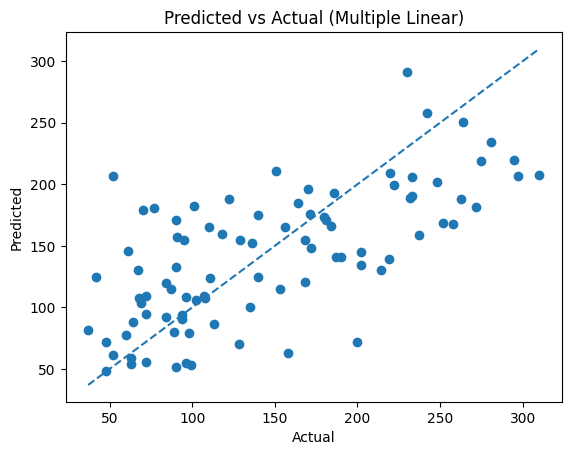

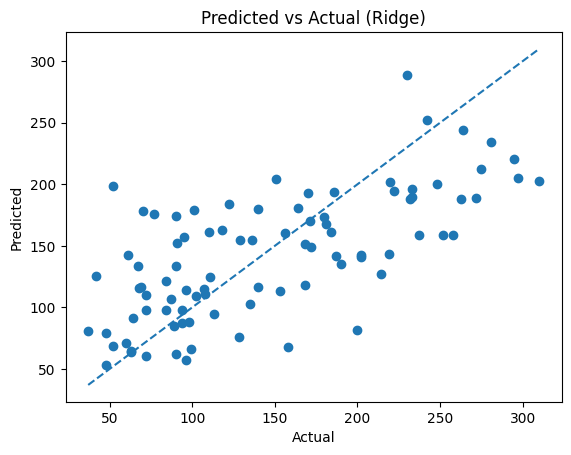

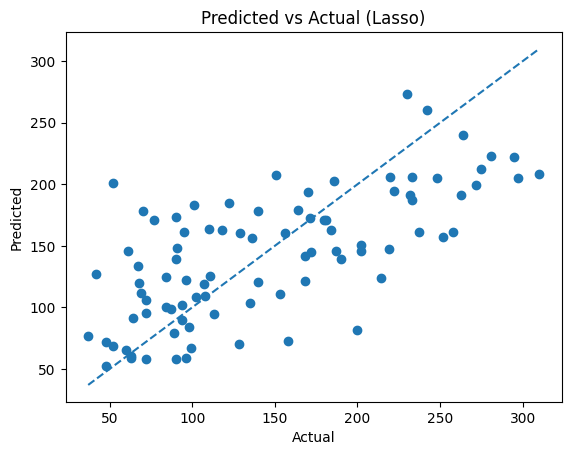

In [6]:

# Visual comparisons (one chart per figure)
# Predicted vs Actual for the three models
plt.scatter(y_te, yp_lin)
mn, mx = min(y_te.min(), yp_lin.min()), max(y_te.max(), yp_lin.max())
plt.plot([mn, mx], [mn, mx], linestyle='--')
plt.title("Predicted vs Actual (Multiple Linear)")
plt.xlabel("Actual"); plt.ylabel("Predicted"); plt.show()

plt.scatter(y_te, yp_ridge)
mn, mx = min(y_te.min(), yp_ridge.min()), max(y_te.max(), yp_ridge.max())
plt.plot([mn, mx], [mn, mx], linestyle='--')
plt.title("Predicted vs Actual (Ridge)")
plt.xlabel("Actual"); plt.ylabel("Predicted"); plt.show()

plt.scatter(y_te, yp_lasso)
mn, mx = min(y_te.min(), yp_lasso.min()), max(y_te.max(), yp_lasso.max())
plt.plot([mn, mx], [mn, mx], linestyle='--')
plt.title("Predicted vs Actual (Lasso)")
plt.xlabel("Actual"); plt.ylabel("Predicted"); plt.show()



## 3. Metrics Summary


In [7]:

summary = pd.DataFrame([
    {"Model": "Simple Linear (1D)", "MAE": lin1_mae, "RMSE": lin1_rmse, "R2": lin1_r2},
    {"Model": "Polynomial d=2 (1D)", "MAE": poly_mae, "RMSE": poly_rmse, "R2": poly_r2},
    {"Model": "Multiple Linear", "MAE": mlr_mae, "RMSE": mlr_rmse, "R2": mlr_r2},
    {"Model": "Ridge", "MAE": ridge_mae, "RMSE": ridge_rmse, "R2": ridge_r2},
    {"Model": "Lasso", "MAE": lasso_mae, "RMSE": lasso_rmse, "R2": lasso_r2},
])
summary


,Model,MAE,RMSE,R2
0,Simple Linear (1D),3.3740,3.7091,0.5523
1,Polynomial d=2 (1D),0.6039,0.7394,0.9822
2,Multiple Linear,42.7941,53.8534,0.4526
3,Ridge,42.9495,53.4933,0.4599
4,Lasso,42.7750,52.9401,0.4710
